<a href="https://colab.research.google.com/github/amansingh4847/NLP/blob/main/unit2/Text%20Classification%20using%20Na%C3%AFve%20Bayes/SVM%20with%20TF-IDF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset:
                                      text sentiment
0      This movie is amazing and wonderful  Positive
1    I really enjoyed this fantastic movie  Positive
2  The film was excellent and entertaining  Positive
3     What a brilliant and beautiful movie  Positive
4         I loved the acting and storyline  Positive

NAIVE BAYES CLASSIFICATION
Accuracy: 80.0 %
              precision    recall  f1-score   support

    Negative       1.00      0.67      0.80         3
    Positive       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80         5
weighted avg       0.87      0.80      0.80         5


SVM CLASSIFICATION
Accuracy: 80.0 %
              precision    recall  f1-score   support

    Negative       1.00      0.67      0.80         3
    Positive       0.67      1.00      0.80         2

    accuracy                           0.80         5
   macro avg       0.83      0.83      0.80   

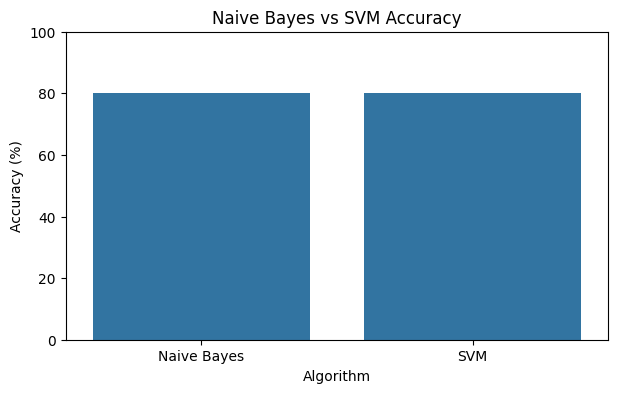

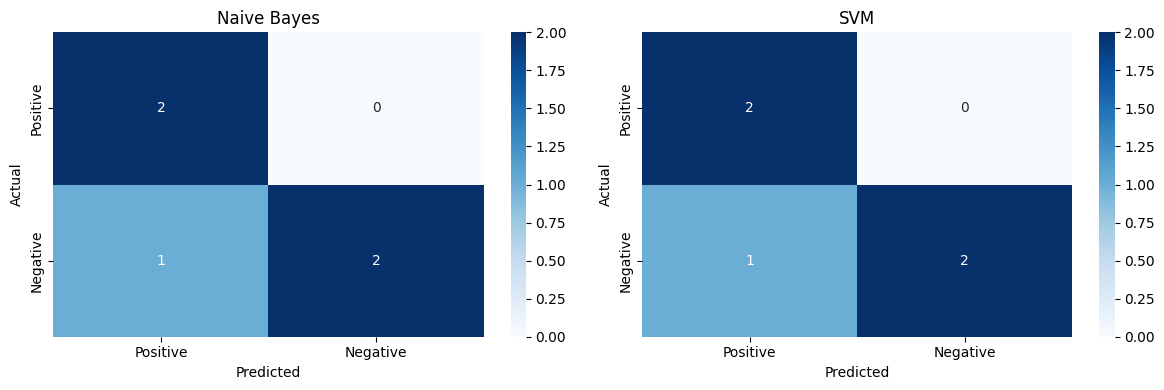


CUSTOM TEXT PREDICTIONS

Text: The movie was absolutely fantastic
Naive Bayes: Positive
SVM: Positive

Text: The product was horrible and disappointing
Naive Bayes: Negative
SVM: Negative

Text classification completed successfully!


In [3]:

# Text Classification using Naive Bayes and SVM with TF-IDF

!pip install -q scikit-learn pandas matplotlib seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Sample dataset
data = {
    'text': [
        "This movie is amazing and wonderful",
        "I really enjoyed this fantastic movie",
        "The film was excellent and entertaining",
        "What a brilliant and beautiful movie",
        "I loved the acting and storyline",
        "This is a great and awesome film",
        "The movie was boring and disappointing",
        "I hated this terrible movie",
        "The film was awful and very bad",
        "What a horrible and boring experience",
        "I disliked the poor acting",
        "This movie is not worth watching",
        "The product quality is excellent",
        "The service was fantastic and helpful",
        "I am very happy with the purchase",
        "The experience was wonderful",
        "The product is defective and useless",
        "I am unhappy with this service",
        "The quality is very poor",
        "This was a terrible experience"
    ],
    'sentiment': [
        'Positive', 'Positive', 'Positive', 'Positive',
        'Positive', 'Positive', 'Negative', 'Negative',
        'Negative', 'Negative', 'Negative', 'Negative',
        'Positive', 'Positive', 'Positive', 'Positive',
        'Negative', 'Negative', 'Negative', 'Negative'
    ]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df.head())

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['sentiment'],
    test_size=0.25,
    random_state=42,
    stratify=df['sentiment']
)

# TF-IDF Vectorization
tfidf = TfidfVectorizer(
    stop_words='english',
    lowercase=True,
    max_features=1000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Train Naive Bayes model
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_predictions = nb_model.predict(X_test_tfidf)

# Train SVM model
svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)
svm_predictions = svm_model.predict(X_test_tfidf)

# Evaluate models
nb_accuracy = accuracy_score(y_test, nb_predictions)
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("\nNAIVE BAYES CLASSIFICATION")
print("Accuracy:", round(nb_accuracy * 100, 2), "%")
print(classification_report(y_test, nb_predictions, zero_division=0))

print("\nSVM CLASSIFICATION")
print("Accuracy:", round(svm_accuracy * 100, 2), "%")
print(classification_report(y_test, svm_predictions, zero_division=0))

# Compare model accuracy
results = pd.DataFrame({
    'Algorithm': ['Naive Bayes', 'SVM'],
    'Accuracy': [nb_accuracy * 100, svm_accuracy * 100]
})

print("\nMODEL ACCURACY COMPARISON")
print(results.to_string(index=False))

plt.figure(figsize=(7, 4))
sns.barplot(data=results, x='Algorithm', y='Accuracy')
plt.title('Naive Bayes vs SVM Accuracy')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.show()

# Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, predictions, title in zip(
    axes,
    [nb_predictions, svm_predictions],
    ['Naive Bayes', 'SVM']
):
    cm = confusion_matrix(
        y_test, predictions,
        labels=['Positive', 'Negative']
    )
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=['Positive', 'Negative'],
        yticklabels=['Positive', 'Negative'],
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

# Test with custom text
test_text = [
    "The movie was absolutely fantastic",
    "The product was horrible and disappointing"
]

test_tfidf = tfidf.transform(test_text)

print("\nCUSTOM TEXT PREDICTIONS")

for text, nb_pred, svm_pred in zip(
    test_text,
    nb_model.predict(test_tfidf),
    svm_model.predict(test_tfidf)
):
    print("\nText:", text)
    print("Naive Bayes:", nb_pred)
    print("SVM:", svm_pred)

print("\nText classification completed successfully!")
